In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Set visualization style
sns.set_theme(style="whitegrid")

print("All libraries imported successfully!")


All libraries imported successfully!


In [6]:

%pip install --upgrade numexpr bottleneck


Note: you may need to restart the kernel to use updated packages.


In [7]:

import os

# Display files in the current working directory
print("Current directory:", os.getcwd())

print("\nAvailable files:")
print(os.listdir())


Current directory: C:\Users\silin\OneDrive\Desktop\Internship\Task1

Available files:
['.ipynb_checkpoints', 'superstore_sales.csv', 'superstore_sales_cleaned.csv', 'Task 1.ipynb']


In [8]:

# Load the Superstore Sales dataset
df = pd.read_csv("superstore_sales.csv")

# Display dataset dimensions
print("Dataset shape:", df.shape)

# Display column names
print("\nColumn names:")
print(df.columns.tolist())

# Display data types
print("\nData types:")
print(df.dtypes)

# Display first five records
print("\nFirst five rows:")
display(df.head())


Dataset shape: (10800, 21)

Column names:
['Row ID', 'Order ID', 'Order Date', 'Ship Date', 'Ship Mode', 'Customer ID', 'Customer Name', 'Segment', 'Country', 'City', 'State', 'Postal Code', 'Region', 'Product ID', 'Category', 'Sub-Category', 'Product Name', 'Sales', 'Quantity', 'Discount', 'Profit']

Data types:
Row ID               str
Order ID             str
Order Date           str
Ship Date            str
Ship Mode            str
Customer ID          str
Customer Name        str
Segment              str
Country              str
City                 str
State                str
Postal Code      float64
Region               str
Product ID           str
Category             str
Sub-Category         str
Product Name         str
Sales            float64
Quantity         float64
Discount         float64
Profit           float64
dtype: object

First five rows:


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,CA-2017-152156,11/8/2017,11/11/2017,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420.0,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600,2.0,0.00,41.9136
1,2,CA-2017-152156,11/8/2017,11/11/2017,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420.0,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3.0,0.00,219.5820
2,3,CA-2017-138688,6/12/2017,6/16/2017,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,...,90036.0,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200,2.0,0.00,6.8714
3,4,US-2016-108966,10/11/2016,10/18/2016,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311.0,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,5.0,0.45,-383.0310
4,5,US-2016-108966,10/11/2016,10/18/2016,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311.0,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680,2.0,0.20,2.5164


In [9]:

# Step 3: Data Quality Assessment

# 1. Missing values
missing_values = pd.DataFrame({
    "Missing Count": df.isnull().sum(),
    "Missing Percentage (%)": (
        df.isnull().sum() / len(df) * 100
    ).round(2)
})

print("MISSING VALUE PROFILE")
display(missing_values)

# 2. Duplicate records
print("\nNumber of duplicate rows:")
print(df.duplicated().sum())

# 3. Unique values
print("\nUnique values per column:")
display(df.nunique())

# 4. Descriptive statistics
print("\nDescriptive statistics:")
display(df.describe())


MISSING VALUE PROFILE


,Missing Count,Missing Percentage (%)
Row ID,0,0.00
Order ID,0,0.00
Order Date,806,7.46
Ship Date,806,7.46
Ship Mode,806,7.46
Customer ID,806,7.46
Customer Name,806,7.46
Segment,806,7.46
Country,806,7.46
City,806,7.46



Number of duplicate rows:
504

Unique values per column:


Row ID           10001
Order ID          5015
Order Date        1236
Ship Date         1334
Ship Mode            4
Customer ID        793
Customer Name      793
Segment              3
Country              1
City               531
State               49
Postal Code        630
Region               4
Product ID        1862
Category             3
Sub-Category        17
Product Name      1850
Sales             5825
Quantity            14
Discount            12
Profit            7287
dtype: int64


Descriptive statistics:


,Postal Code,Sales,Quantity,Discount,Profit
count,9983.000000,9994.000000,9994.000000,9994.000000,9994.000000
mean,55245.233297,229.858001,3.789574,0.156203,28.656896
std,32038.715955,623.245101,2.225110,0.206452,234.260108
min,1040.000000,0.444000,1.000000,0.000000,-6599.978000
25%,23223.000000,17.280000,2.000000,0.000000,1.728750
50%,57103.000000,54.490000,3.000000,0.200000,8.666500
75%,90008.000000,209.940000,5.000000,0.200000,29.364000
max,99301.000000,22638.480000,14.000000,0.800000,8399.976000


In [10]:

# Step 4: Investigate missing and duplicate records

# 1. Inspect records missing sales values
missing_sales = df[df["Sales"].isna()]

print("Records missing Sales:", len(missing_sales))
display(missing_sales.head(10))

# 2. Check whether missing records contain
# only Row ID and Order ID
other_columns = [
    col for col in df.columns
    if col not in ["Row ID", "Order ID"]
]

fully_incomplete = df[other_columns].isna().all(axis=1)

print("\nRecords missing all other fields:")
print(fully_incomplete.sum())

# 3. Inspect exact duplicate records
duplicates = df[df.duplicated(keep=False)]

print("\nRows belonging to duplicate groups:")
print(len(duplicates))

display(duplicates.head(10))

# 4. Check duplicate Row IDs
print("\nDuplicate Row IDs:")
print(df["Row ID"].duplicated().sum())


Records missing Sales: 806


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
9994,Person,Region,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9995,Anna Andreadi,West,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9996,Chuck Magee,East,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9997,Kelly Williams,Central,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9998,Cassandra Brandow,South,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9999,Returned,Order ID,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
10000,Yes,CA-2015-100762,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
10001,Yes,CA-2015-100762,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
10002,Yes,CA-2015-100762,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
10003,Yes,CA-2015-100762,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN



Records missing all other fields:
806

Rows belonging to duplicate groups:
710


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
10000,Yes,CA-2015-100762,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
10001,Yes,CA-2015-100762,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
10002,Yes,CA-2015-100762,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
10003,Yes,CA-2015-100762,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
10005,Yes,CA-2015-102652,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
10006,Yes,CA-2015-102652,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
10007,Yes,CA-2015-102652,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
10008,Yes,CA-2015-102652,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
10010,Yes,CA-2015-103744,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
10011,Yes,CA-2015-103744,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN



Duplicate Row IDs:
799


In [11]:

# Create a copy of the original dataset
df_original = df.copy()

# Retain records with sales information
df_clean = df[df["Sales"].notna()].copy()

# Compare dataset sizes
print("Original dataset:", df_original.shape)
print("Cleaned sales dataset:", df_clean.shape)

# Check missing values after filtering
print("\nRemaining missing values:")
display(df_clean.isnull().sum())

# Check exact duplicates
print("\nRemaining exact duplicates:")
print(df_clean.duplicated().sum())

# Check unique Row IDs
print("\nUnique Row IDs:")
print(df_clean["Row ID"].nunique())


Original dataset: (10800, 21)
Cleaned sales dataset: (9994, 21)

Remaining missing values:


Row ID            0
Order ID          0
Order Date        0
Ship Date         0
Ship Mode         0
Customer ID       0
Customer Name     0
Segment           0
Country           0
City              0
State             0
Postal Code      11
Region            0
Product ID        0
Category          0
Sub-Category      0
Product Name      0
Sales             0
Quantity          0
Discount          0
Profit            0
dtype: int64


Remaining exact duplicates:
0

Unique Row IDs:
9994


In [12]:

# Convert date columns to datetime
df_clean["Order Date"] = pd.to_datetime(
    df_clean["Order Date"],
    format="%m/%d/%Y",
    errors="coerce"
)

df_clean["Ship Date"] = pd.to_datetime(
    df_clean["Ship Date"],
    format="%m/%d/%Y",
    errors="coerce"
)

# Extract year and month
df_clean["Year"] = df_clean["Order Date"].dt.year
df_clean["Month"] = df_clean["Order Date"].dt.month

# Create Year-Month variable
df_clean["Year-Month"] = (
    df_clean["Order Date"].dt.to_period("M")
)

# Calculate shipping duration
df_clean["Shipping Days"] = (
    df_clean["Ship Date"] - df_clean["Order Date"]
).dt.days

# Verify transformation
print("Updated data types:")
print(df_clean[
    ["Order Date", "Ship Date", "Year",
     "Month", "Year-Month", "Shipping Days"]
].dtypes)

print("\nMissing dates after conversion:")
print(df_clean[["Order Date", "Ship Date"]].isna().sum())

print("\nDate range:")
print("Earliest order:", df_clean["Order Date"].min())
print("Latest order:", df_clean["Order Date"].max())

print("\nFirst five records:")
display(df_clean[
    ["Order Date", "Ship Date", "Year",
     "Month", "Year-Month", "Shipping Days"]
].head())


Updated data types:
Order Date       datetime64[us]
Ship Date        datetime64[us]
Year                      int32
Month                     int32
Year-Month            period[M]
Shipping Days             int64
dtype: object

Missing dates after conversion:
Order Date    0
Ship Date     0
dtype: int64

Date range:
Earliest order: 2015-01-03 00:00:00
Latest order: 2018-12-30 00:00:00

First five records:


,Order Date,Ship Date,Year,Month,Year-Month,Shipping Days
0,2017-11-08,2017-11-11,2017,11,2017-11,3
1,2017-11-08,2017-11-11,2017,11,2017-11,3
2,2017-06-12,2017-06-16,2017,6,2017-06,4
3,2016-10-11,2016-10-18,2016,10,2016-10,7
4,2016-10-11,2016-10-18,2016,10,2016-10,7


In [13]:

# Step 6.1: Business Performance Indicators

total_sales = df_clean["Sales"].sum()
total_profit = df_clean["Profit"].sum()
total_orders = df_clean["Order ID"].nunique()
total_customers = df_clean["Customer ID"].nunique()
total_quantity = df_clean["Quantity"].sum()

profit_margin = (total_profit / total_sales) * 100

average_order_value = total_sales / total_orders

# Display results
print("SUPERSTORE BUSINESS PERFORMANCE")
print("-" * 40)

print(f"Total Sales Revenue: ${total_sales:,.2f}")
print(f"Total Profit: ${total_profit:,.2f}")
print(f"Total Orders: {total_orders:,}")
print(f"Total Customers: {total_customers:,}")
print(f"Total Units Sold: {total_quantity:,.0f}")
print(f"Overall Profit Margin: {profit_margin:.2f}%")
print(f"Average Order Value: ${average_order_value:,.2f}")


SUPERSTORE BUSINESS PERFORMANCE
----------------------------------------
Total Sales Revenue: $2,297,200.86
Total Profit: $286,397.02
Total Orders: 5,009
Total Customers: 793
Total Units Sold: 37,873
Overall Profit Margin: 12.47%
Average Order Value: $458.61


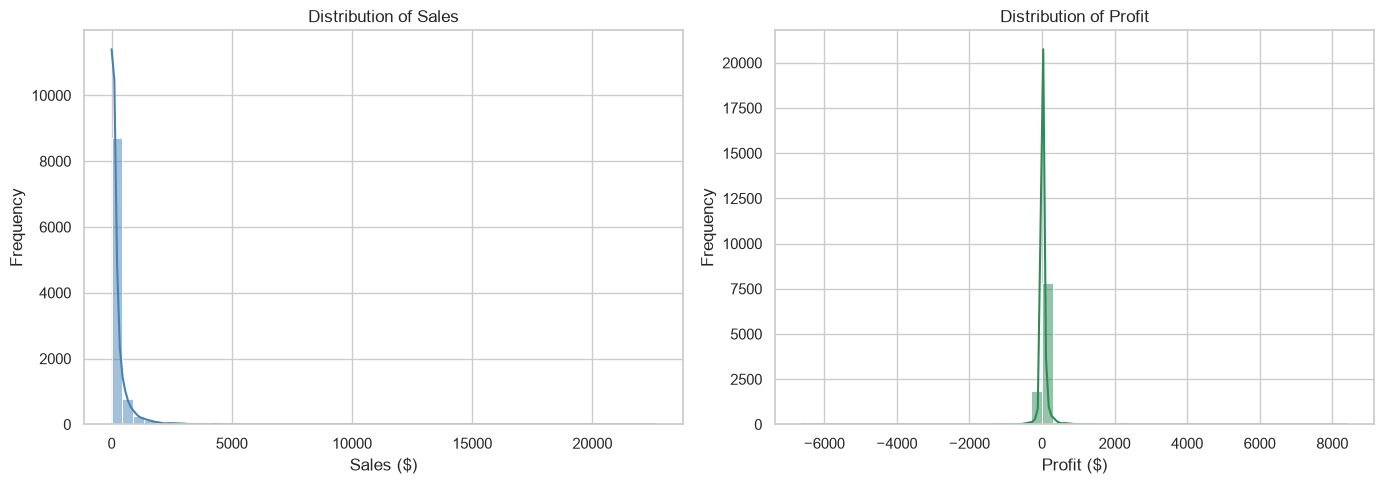

Sales Skewness: 12.973
Profit Skewness: 7.561

Profitable transaction lines: 8058
Loss-making transaction lines: 1871
Zero-profit transaction lines: 65


In [14]:

# Step 6.2: Sales and Profit Distribution

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Sales distribution
sns.histplot(
    df_clean["Sales"],
    bins=50,
    kde=True,
    color="steelblue",
    ax=axes[0]
)

axes[0].set_title("Distribution of Sales")
axes[0].set_xlabel("Sales ($)")
axes[0].set_ylabel("Frequency")

# Profit distribution
sns.histplot(
    df_clean["Profit"],
    bins=50,
    kde=True,
    color="seagreen",
    ax=axes[1]
)

axes[1].set_title("Distribution of Profit")
axes[1].set_xlabel("Profit ($)")
axes[1].set_ylabel("Frequency")

plt.tight_layout()
plt.show()

# Calculate skewness
print("Sales Skewness:",
      round(df_clean["Sales"].skew(), 3))

print("Profit Skewness:",
      round(df_clean["Profit"].skew(), 3))

# Count profitable and loss-making transactions
print("\nProfitable transaction lines:",
      (df_clean["Profit"] > 0).sum())

print("Loss-making transaction lines:",
      (df_clean["Profit"] < 0).sum())

print("Zero-profit transaction lines:",
      (df_clean["Profit"] == 0).sum())


Sales Outlier Analysis
-------------------------
Q1: $17.28
Q3: $209.94
IQR: $192.66
Lower Bound: $-271.71
Upper Bound: $498.93
Number of Outliers: 1167

Percentage of Outliers: 11.68


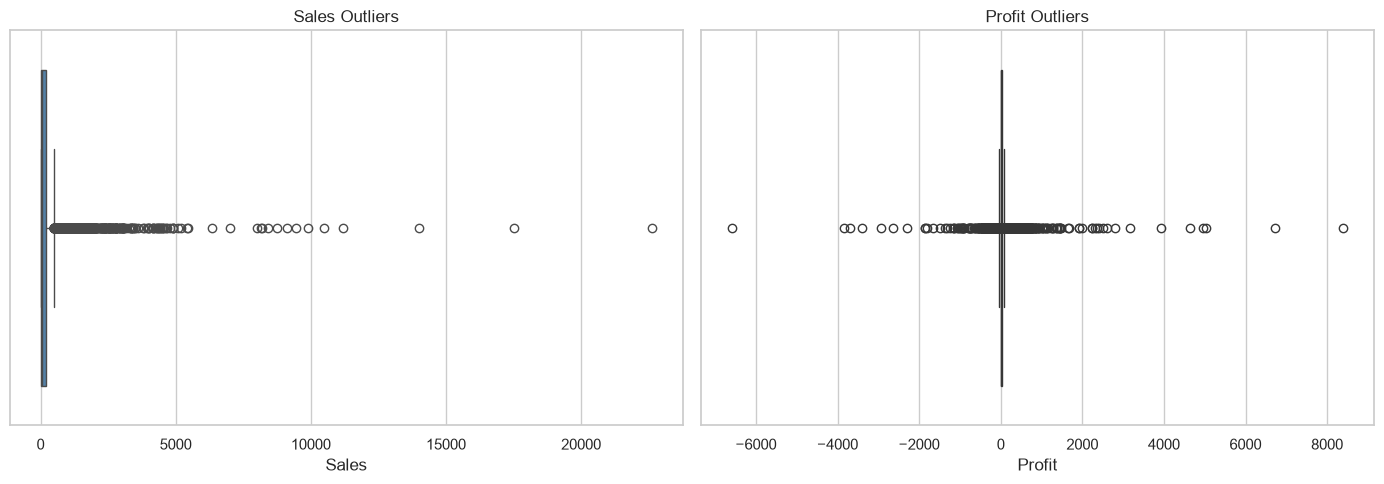

In [15]:

# Step 6.3: Outlier Detection

# Calculate IQR for Sales
Q1 = df_clean["Sales"].quantile(0.25)
Q3 = df_clean["Sales"].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

# Identify sales outliers
sales_outliers = df_clean[
    (df_clean["Sales"] < lower_bound) |
    (df_clean["Sales"] > upper_bound)
]

print("Sales Outlier Analysis")
print("-------------------------")
print(f"Q1: ${Q1:.2f}")
print(f"Q3: ${Q3:.2f}")
print(f"IQR: ${IQR:.2f}")
print(f"Lower Bound: ${lower_bound:.2f}")
print(f"Upper Bound: ${upper_bound:.2f}")
print(f"Number of Outliers: {len(sales_outliers)}")

print("\nPercentage of Outliers:",
      round(len(sales_outliers) / len(df_clean) * 100, 2))

# Visualize sales and profit outliers
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.boxplot(
    x=df_clean["Sales"],
    ax=axes[0],
    color="steelblue"
)
axes[0].set_title("Sales Outliers")

sns.boxplot(
    x=df_clean["Profit"],
    ax=axes[1],
    color="seagreen"
)
axes[1].set_title("Profit Outliers")

plt.tight_layout()
plt.show()


In [16]:

# Step 7.1: Customer Purchase Volume Analysis

customer_analysis = df_clean.groupby(
    ["Customer ID", "Customer Name"]
).agg(
    Total_Sales=("Sales", "sum"),
    Total_Profit=("Profit", "sum"),
    Total_Quantity=("Quantity", "sum"),
    Total_Orders=("Order ID", "nunique")
).reset_index()

# Calculate average order value
customer_analysis["Average_Order_Value"] = (
    customer_analysis["Total_Sales"] /
    customer_analysis["Total_Orders"]
)

# Sort customers by total sales
customer_analysis = customer_analysis.sort_values(
    by="Total_Sales",
    ascending=False
)

print("CUSTOMER PURCHASE VOLUME ANALYSIS")
print("-" * 45)

print("Total unique customers:",
      len(customer_analysis))

print("\nTop 10 customers by total sales:")
display(customer_analysis.head(10))

# Customer summary statistics
print("\nCustomer spending statistics:")
display(customer_analysis[
    ["Total_Sales", "Total_Profit",
     "Total_Quantity", "Total_Orders"]
].describe())


CUSTOMER PURCHASE VOLUME ANALYSIS
---------------------------------------------
Total unique customers: 793

Top 10 customers by total sales:


,Customer ID,Customer Name,Total_Sales,Total_Profit,Total_Quantity,Total_Orders,Average_Order_Value
700,SM-20320,Sean Miller,25043.050,-1980.7393,50.0,5,5008.610000
741,TC-20980,Tamara Chand,19052.218,8981.3239,42.0,5,3810.443600
621,RB-19360,Raymond Buch,15117.339,6976.0959,71.0,6,2519.556500
730,TA-21385,Tom Ashbrook,14595.620,4703.7883,36.0,4,3648.905000
6,AB-10105,Adrian Barton,14473.571,5444.8055,73.0,10,1447.357100
434,KL-16645,Ken Lonsdale,14175.229,806.8550,113.0,12,1181.269083
669,SC-20095,Sanjit Chand,14142.334,5757.4119,87.0,9,1571.370444
327,HL-15040,Hunter Lopez,12873.298,5622.4292,50.0,6,2145.549667
683,SE-20110,Sanjit Engle,12209.438,2650.6769,78.0,11,1109.948909
131,CC-12370,Christopher Conant,12129.072,2177.0493,34.0,5,2425.814400



Customer spending statistics:


,Total_Sales,Total_Profit,Total_Quantity,Total_Orders
count,793.000000,793.000000,793.000000,793.000000
mean,2896.848500,361.156396,47.759142,6.316520
std,2628.670117,894.261812,24.842915,2.550885
min,4.833000,-6626.389500,2.000000,1.000000
25%,1146.050000,36.613100,30.000000,5.000000
50%,2256.394000,227.833800,44.000000,6.000000
75%,3785.276000,560.007800,63.000000,8.000000
max,25043.050000,8981.323900,150.000000,17.000000


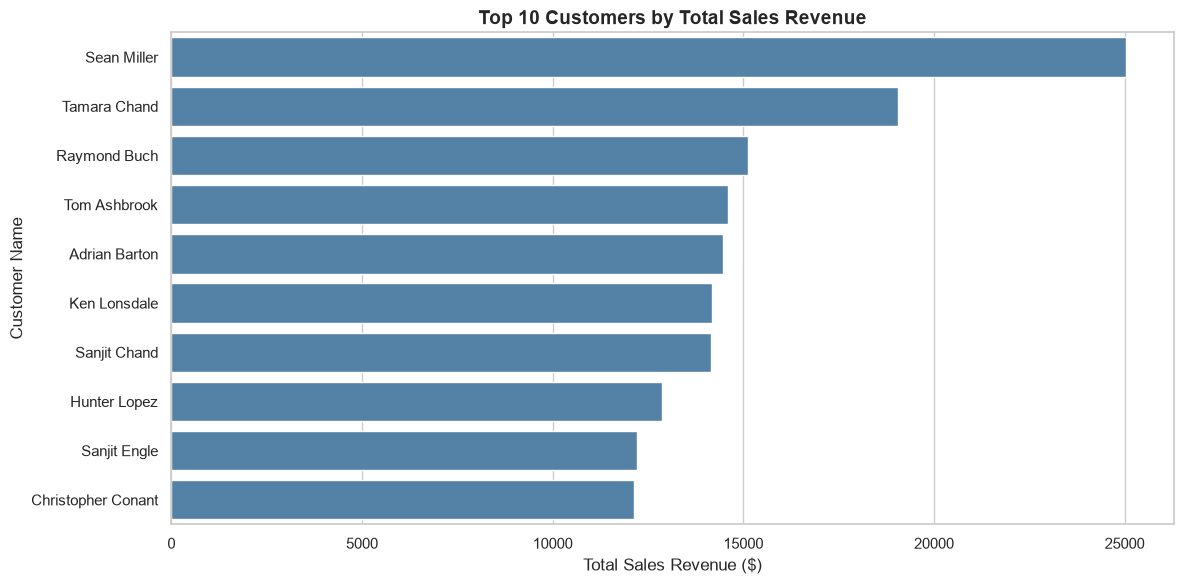

In [17]:

# Step 7.2: Top 10 Customers Visualization

top10_customers = customer_analysis.head(10)

plt.figure(figsize=(12, 6))

sns.barplot(
    data=top10_customers,
    x="Total_Sales",
    y="Customer Name",
    color="steelblue"
)

plt.title(
    "Top 10 Customers by Total Sales Revenue",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel("Total Sales Revenue ($)")
plt.ylabel("Customer Name")

plt.tight_layout()
plt.show()


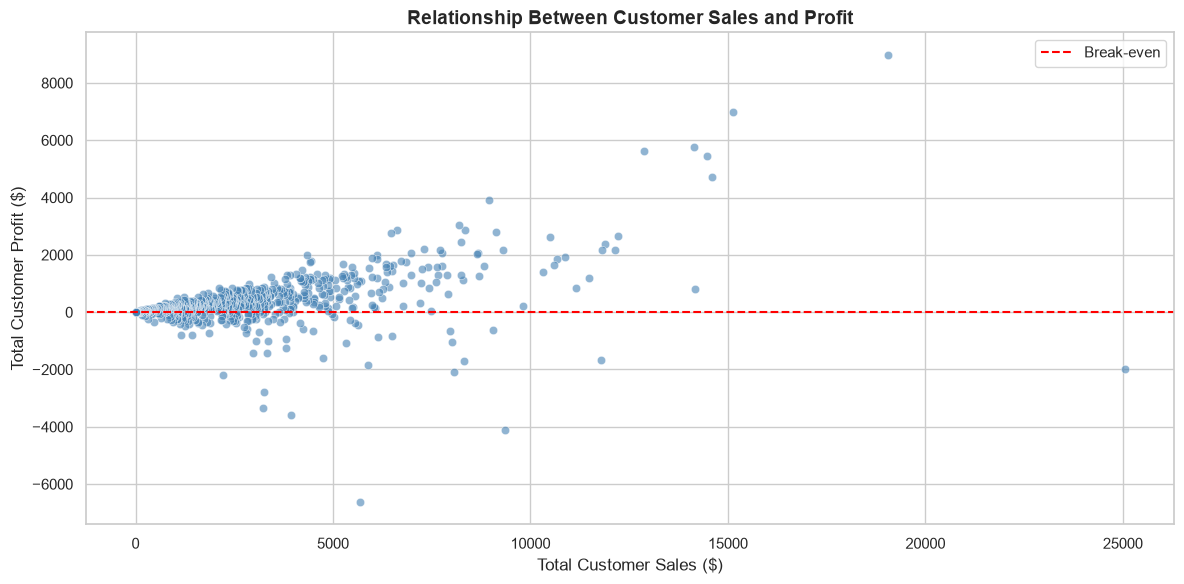

Sales-Profit Correlation: 0.506
Customers with negative total profit: 155
Percentage of loss-making customers: 19.55 %


In [18]:

# Step 7.3: Customer Sales vs Profit

plt.figure(figsize=(12, 6))

sns.scatterplot(
    data=customer_analysis,
    x="Total_Sales",
    y="Total_Profit",
    alpha=0.6,
    color="steelblue"
)

plt.axhline(
    y=0,
    color="red",
    linestyle="--",
    label="Break-even"
)

plt.title(
    "Relationship Between Customer Sales and Profit",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel("Total Customer Sales ($)")
plt.ylabel("Total Customer Profit ($)")

plt.legend()
plt.tight_layout()
plt.show()

# Calculate correlation
correlation = customer_analysis[
    "Total_Sales"
].corr(customer_analysis["Total_Profit"])

print(
    f"Sales-Profit Correlation: {correlation:.3f}"
)

# Count loss-making customers
loss_customers = (
    customer_analysis["Total_Profit"] < 0
).sum()

print("Customers with negative total profit:",
      loss_customers)

print(
    "Percentage of loss-making customers:",
    round(
        loss_customers / len(customer_analysis) * 100,
        2
    ),
    "%"
)


In [19]:

# Step 8.1: Monthly Sales Analysis

monthly_sales = df_clean.groupby(
    "Year-Month"
).agg(
    Total_Sales=("Sales", "sum"),
    Total_Profit=("Profit", "sum"),
    Total_Orders=("Order ID", "nunique")
).reset_index()

# Convert Year-Month to datetime for plotting
monthly_sales["Date"] = (
    monthly_sales["Year-Month"].dt.to_timestamp()
)

# Display monthly results
print("MONTHLY SALES PERFORMANCE")
print("-" * 45)

display(monthly_sales.head(12))

# Identify highest and lowest sales months
highest_month = monthly_sales.loc[
    monthly_sales["Total_Sales"].idxmax()
]

lowest_month = monthly_sales.loc[
    monthly_sales["Total_Sales"].idxmin()
]

print("\nHighest sales month:")
print(highest_month[["Year-Month", "Total_Sales"]])

print("\nLowest sales month:")
print(lowest_month[["Year-Month", "Total_Sales"]])


MONTHLY SALES PERFORMANCE
---------------------------------------------


,Year-Month,Total_Sales,Total_Profit,Total_Orders,Date
0,2015-01,14236.8950,2450.1907,32,2015-01-01
1,2015-02,4519.8920,862.3084,28,2015-02-01
2,2015-03,55691.0090,498.7299,71,2015-03-01
3,2015-04,28295.3450,3488.8352,66,2015-04-01
4,2015-05,23648.2870,2738.7096,69,2015-05-01
5,2015-06,34595.1276,4976.5244,66,2015-06-01
6,2015-07,33946.3930,-841.4826,65,2015-07-01
7,2015-08,27909.4685,5318.1050,72,2015-08-01
8,2015-09,81777.3508,8328.0994,130,2015-09-01
9,2015-10,31453.3930,3448.2573,78,2015-10-01



Highest sales month:
Year-Month        2018-11
Total_Sales    118447.825
Name: 46, dtype: object

Lowest sales month:
Year-Month      2015-02
Total_Sales    4519.892
Name: 1, dtype: object


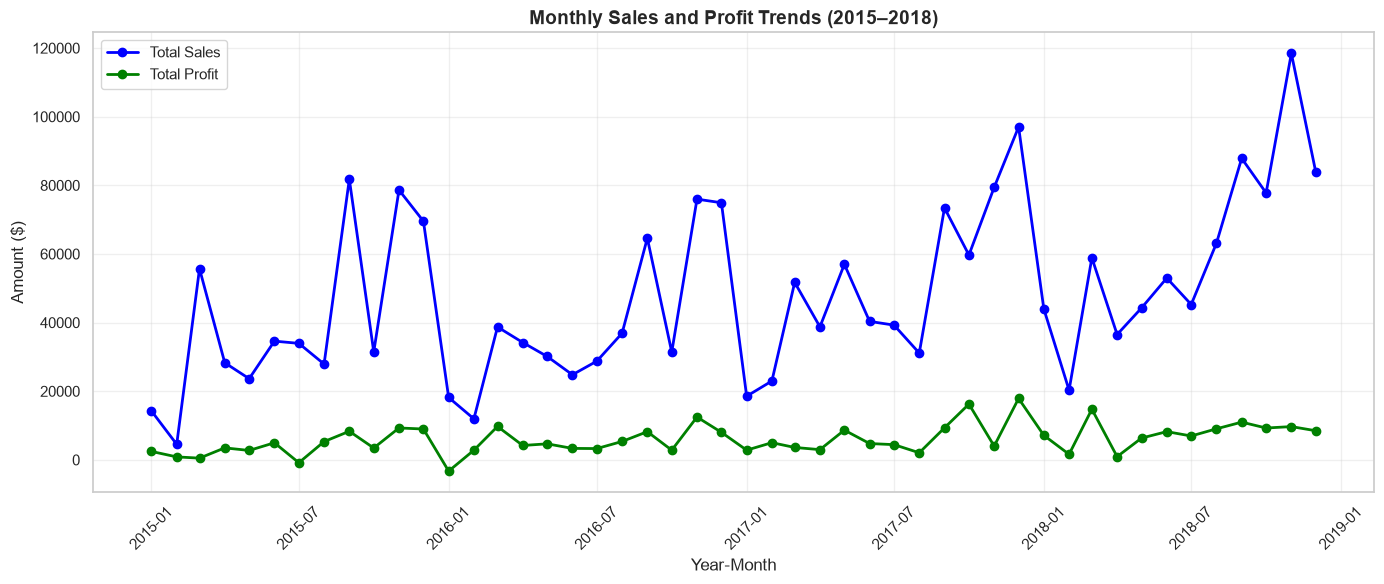

In [20]:

# Graph 1: Monthly Sales and Profit Trends

plt.figure(figsize=(14, 6))

plt.plot(
    monthly_sales["Date"],
    monthly_sales["Total_Sales"],
    marker="o",
    color="blue",
    linewidth=2,
    label="Total Sales"
)

plt.plot(
    monthly_sales["Date"],
    monthly_sales["Total_Profit"],
    marker="o",
    color="green",
    linewidth=2,
    label="Total Profit"
)

plt.title(
    "Monthly Sales and Profit Trends (2015–2018)",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel("Year-Month")
plt.ylabel("Amount ($)")
plt.xticks(rotation=45)
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


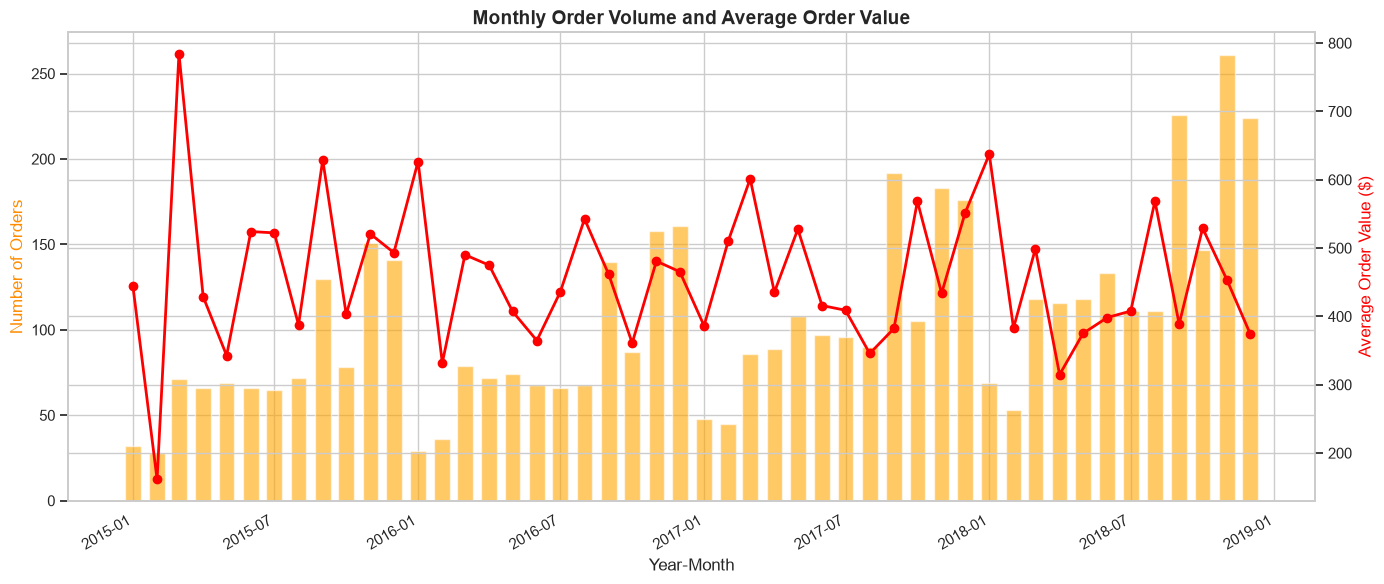

In [21]:

# Graph 2: Monthly Orders and Average Order Value

monthly_sales["Average_Order_Value"] = (
    monthly_sales["Total_Sales"] /
    monthly_sales["Total_Orders"]
)

fig, ax1 = plt.subplots(figsize=(14, 6))

# Bar chart: Total Orders
ax1.bar(
    monthly_sales["Date"],
    monthly_sales["Total_Orders"],
    width=20,
    color="orange",
    alpha=0.6,
    label="Total Orders"
)

ax1.set_xlabel("Year-Month")
ax1.set_ylabel("Number of Orders", color="darkorange")

# Secondary axis: Average Order Value
ax2 = ax1.twinx()

ax2.plot(
    monthly_sales["Date"],
    monthly_sales["Average_Order_Value"],
    color="red",
    marker="o",
    linewidth=2,
    label="Average Order Value"
)

ax2.set_ylabel("Average Order Value ($)", color="red")

plt.title(
    "Monthly Order Volume and Average Order Value",
    fontsize=14,
    fontweight="bold"
)

fig.autofmt_xdate()
plt.tight_layout()
plt.show()


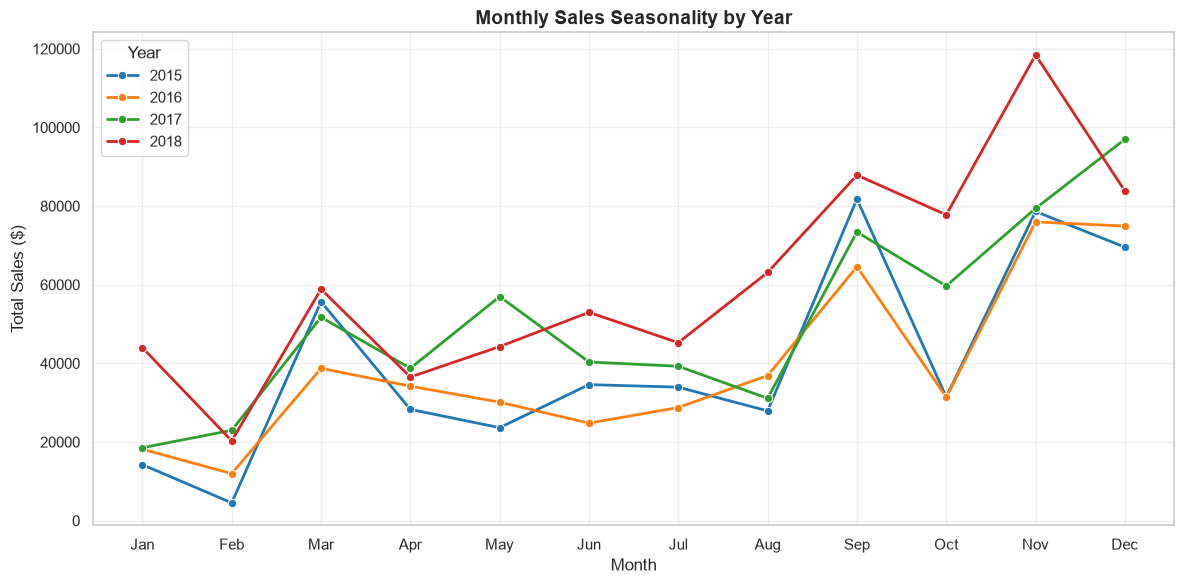

In [22]:

# Graph 3: Monthly Sales Seasonality by Year

seasonality = df_clean.groupby(
    ["Year", "Month"]
)["Sales"].sum().reset_index()

plt.figure(figsize=(12, 6))

sns.lineplot(
    data=seasonality,
    x="Month",
    y="Sales",
    hue="Year",
    marker="o",
    linewidth=2,
    palette="tab10"
)

plt.title(
    "Monthly Sales Seasonality by Year",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel("Month")
plt.ylabel("Total Sales ($)")

plt.xticks(
    range(1, 13),
    [
        "Jan", "Feb", "Mar", "Apr",
        "May", "Jun", "Jul", "Aug",
        "Sep", "Oct", "Nov", "Dec"
    ]
)

plt.legend(title="Year")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


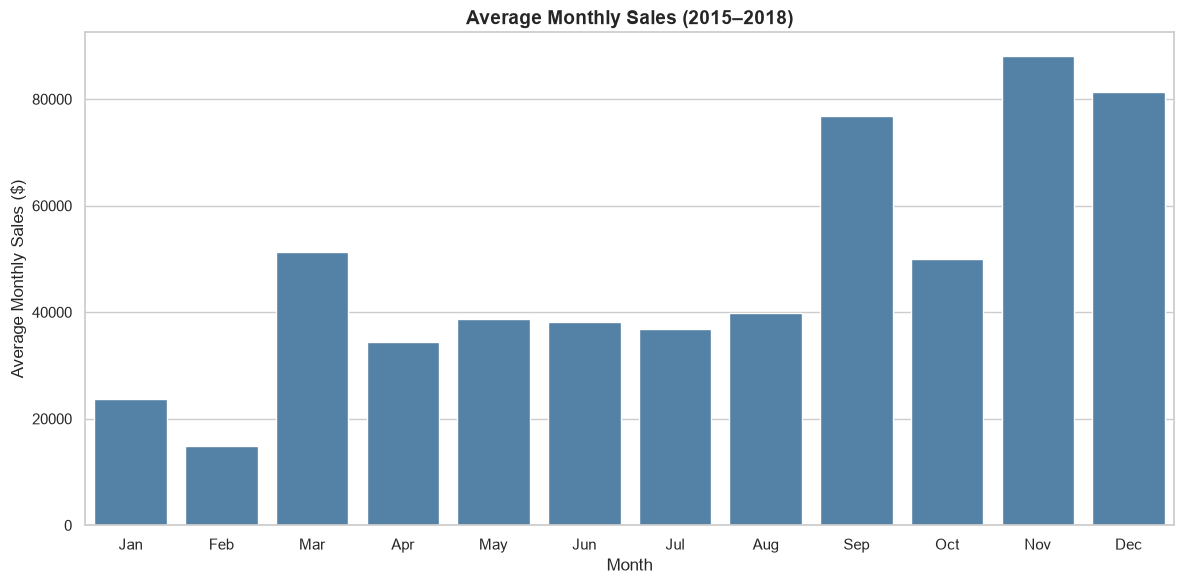

Average Monthly Sales:


,Month,Sales,Month_Name
0,1,23731.208900,Jan
1,2,14937.812850,Feb
2,3,51251.372200,Mar
3,4,34440.532150,Apr
4,5,38757.202925,May
5,6,38179.669825,Jun
6,7,36809.524250,Jul
7,8,39761.015750,Aug
8,9,76912.486425,Sep
9,10,50080.746175,Oct


In [23]:

# Graph 4: Average Monthly Sales (2015–2018)

average_monthly_sales = (
    seasonality.groupby("Month")["Sales"]
    .mean()
    .reset_index()
)

month_names = [
    "Jan", "Feb", "Mar", "Apr",
    "May", "Jun", "Jul", "Aug",
    "Sep", "Oct", "Nov", "Dec"
]

average_monthly_sales["Month_Name"] = (
    average_monthly_sales["Month"]
    .map(dict(enumerate(month_names, start=1)))
)

plt.figure(figsize=(12, 6))

sns.barplot(
    data=average_monthly_sales,
    x="Month_Name",
    y="Sales",
    color="steelblue"
)

plt.title(
    "Average Monthly Sales (2015–2018)",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel("Month")
plt.ylabel("Average Monthly Sales ($)")
plt.tight_layout()
plt.show()

print("Average Monthly Sales:")
display(average_monthly_sales)


In [24]:

# Step 9.1: Category-wise Sales and Profit

category_analysis = df_clean.groupby(
    "Category"
).agg(
    Total_Sales=("Sales", "sum"),
    Total_Profit=("Profit", "sum"),
    Total_Quantity=("Quantity", "sum"),
    Total_Orders=("Order ID", "nunique")
).reset_index()

# Calculate profit margin
category_analysis["Profit_Margin"] = (
    category_analysis["Total_Profit"] /
    category_analysis["Total_Sales"] * 100
)

# Calculate contribution to total revenue
category_analysis["Revenue_Share"] = (
    category_analysis["Total_Sales"] /
    df_clean["Sales"].sum() * 100
)

# Sort categories by revenue
category_analysis = category_analysis.sort_values(
    "Total_Sales",
    ascending=False
)

print("CATEGORY-WISE SALES PERFORMANCE")
print("-" * 45)

display(category_analysis.round(2))


CATEGORY-WISE SALES PERFORMANCE
---------------------------------------------


,Category,Total_Sales,Total_Profit,Total_Quantity,Total_Orders,Profit_Margin,Revenue_Share
2,Technology,836154.03,145454.95,6939.0,1544,17.40,36.4
0,Furniture,741999.80,18451.27,8028.0,1764,2.49,32.3
1,Office Supplies,719047.03,122490.80,22906.0,3742,17.04,31.3


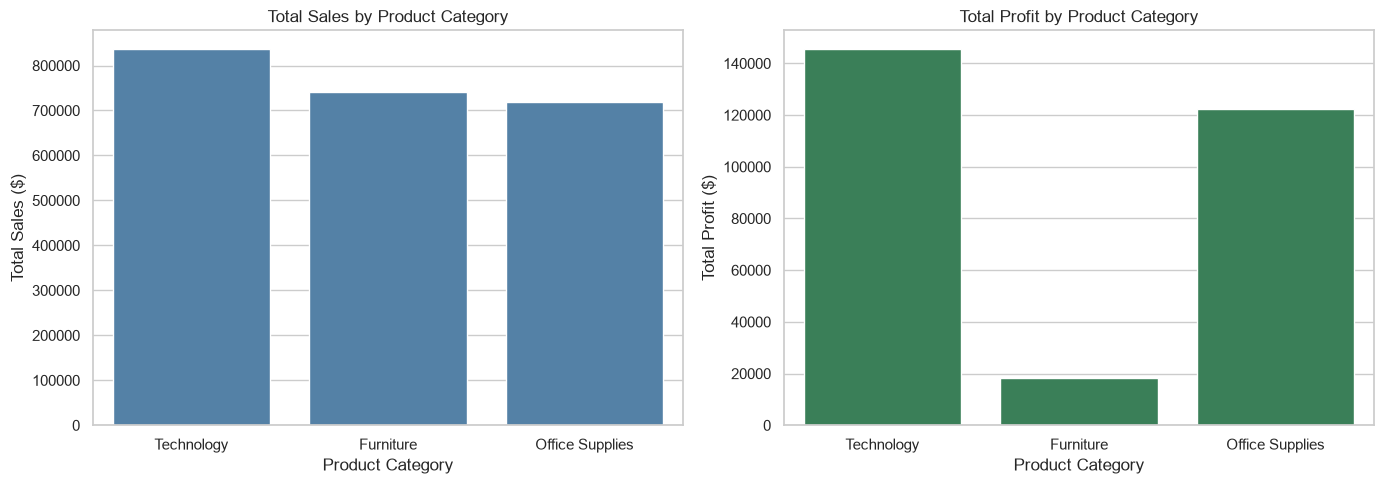

In [25]:

# Step 9.2: Category Revenue and Profit Visualization

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Revenue by category
sns.barplot(
    data=category_analysis,
    x="Category",
    y="Total_Sales",
    color="steelblue",
    ax=axes[0]
)

axes[0].set_title("Total Sales by Product Category")
axes[0].set_xlabel("Product Category")
axes[0].set_ylabel("Total Sales ($)")

# Profit by category
sns.barplot(
    data=category_analysis,
    x="Category",
    y="Total_Profit",
    color="seagreen",
    ax=axes[1]
)

axes[1].set_title("Total Profit by Product Category")
axes[1].set_xlabel("Product Category")
axes[1].set_ylabel("Total Profit ($)")

plt.tight_layout()
plt.show()


In [26]:

# Step 10.1: Regional Sales Performance

region_analysis = df_clean.groupby(
    "Region"
).agg(
    Total_Sales=("Sales", "sum"),
    Total_Profit=("Profit", "sum"),
    Total_Quantity=("Quantity", "sum"),
    Total_Orders=("Order ID", "nunique")
).reset_index()

# Calculate profit margin
region_analysis["Profit_Margin"] = (
    region_analysis["Total_Profit"] /
    region_analysis["Total_Sales"] * 100
)

# Calculate revenue contribution
region_analysis["Revenue_Share"] = (
    region_analysis["Total_Sales"] /
    df_clean["Sales"].sum() * 100
)

# Sort by total sales
region_analysis = region_analysis.sort_values(
    "Total_Sales",
    ascending=False
)

print("REGIONAL SALES PERFORMANCE")
print("-" * 45)

display(region_analysis.round(2))


REGIONAL SALES PERFORMANCE
---------------------------------------------


,Region,Total_Sales,Total_Profit,Total_Quantity,Total_Orders,Profit_Margin,Revenue_Share
3,West,725457.82,108418.45,12266.0,1611,14.94,31.58
1,East,678781.24,91522.78,10618.0,1401,13.48,29.55
0,Central,501239.89,39706.36,8780.0,1175,7.92,21.82
2,South,391721.90,46749.43,6209.0,822,11.93,17.05


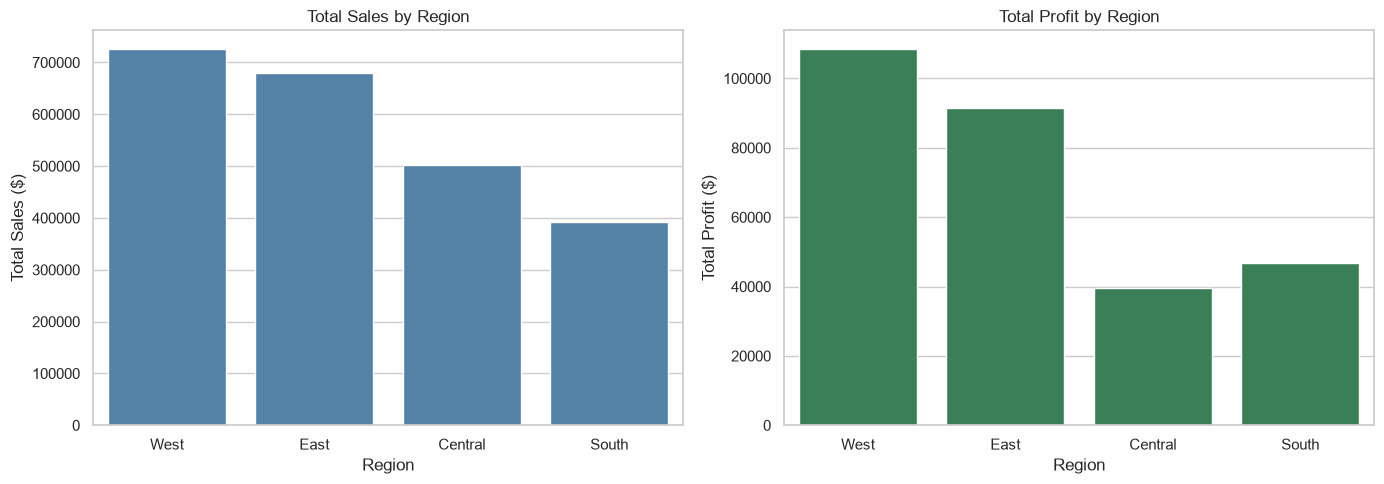

In [27]:

# Step 10.2: Regional Sales and Profit Visualization

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.barplot(
    data=region_analysis,
    x="Region",
    y="Total_Sales",
    color="steelblue",
    ax=axes[0]
)

axes[0].set_title("Total Sales by Region")
axes[0].set_xlabel("Region")
axes[0].set_ylabel("Total Sales ($)")

sns.barplot(
    data=region_analysis,
    x="Region",
    y="Total_Profit",
    color="seagreen",
    ax=axes[1]
)

axes[1].set_title("Total Profit by Region")
axes[1].set_xlabel("Region")
axes[1].set_ylabel("Total Profit ($)")

plt.tight_layout()
plt.show()


In [28]:

# Step 10.3: Customer Segment Performance

segment_analysis = df_clean.groupby(
    "Segment"
).agg(
    Total_Sales=("Sales", "sum"),
    Total_Profit=("Profit", "sum"),
    Total_Orders=("Order ID", "nunique")
).reset_index()

segment_analysis["Profit_Margin"] = (
    segment_analysis["Total_Profit"] /
    segment_analysis["Total_Sales"] * 100
)

segment_analysis = segment_analysis.sort_values(
    "Total_Sales",
    ascending=False
)

print("CUSTOMER SEGMENT PERFORMANCE")
print("-" * 45)

display(segment_analysis.round(2))


CUSTOMER SEGMENT PERFORMANCE
---------------------------------------------


,Segment,Total_Sales,Total_Profit,Total_Orders,Profit_Margin
0,Consumer,1161401.34,134119.21,2586,11.55
1,Corporate,706146.37,91979.13,1514,13.03
2,Home Office,429653.15,60298.68,909,14.03


In [29]:

# Step 11.1: Discount Sensitivity Analysis

# Calculate Pearson correlation
discount_profit_corr = df_clean[
    "Discount"
].corr(df_clean["Profit"])

print("DISCOUNT SENSITIVITY ANALYSIS")
print("-" * 45)

print(
    f"Discount-Profit Correlation: "
    f"{discount_profit_corr:.3f}"
)

# Group by exact discount levels
discount_analysis = df_clean.groupby(
    "Discount"
).agg(
    Total_Sales=("Sales", "sum"),
    Total_Profit=("Profit", "sum"),
    Average_Profit=("Profit", "mean"),
    Transaction_Count=("Profit", "count")
).reset_index()

# Calculate profit margin
discount_analysis["Profit_Margin"] = (
    discount_analysis["Total_Profit"] /
    discount_analysis["Total_Sales"] * 100
)

print("\nProfitability by Discount Level:")
display(discount_analysis.round(2))


DISCOUNT SENSITIVITY ANALYSIS
---------------------------------------------
Discount-Profit Correlation: -0.219

Profitability by Discount Level:


,Discount,Total_Sales,Total_Profit,Average_Profit,Transaction_Count,Profit_Margin
0,0.00,1087908.47,320987.60,66.90,4798,29.51
1,0.10,54369.35,9029.18,96.06,94,16.61
2,0.15,27558.52,1418.99,27.29,52,5.15
3,0.20,764594.37,90337.31,24.70,3657,11.82
4,0.30,103226.66,-10369.28,-45.68,227,-10.05
5,0.32,14493.46,-2391.14,-88.56,27,-16.50
6,0.40,116417.78,-23057.05,-111.93,206,-19.81
7,0.45,5484.97,-2493.11,-226.65,11,-45.45
8,0.50,58918.54,-20506.43,-310.70,66,-34.80
9,0.60,6644.70,-5944.66,-43.08,138,-89.46


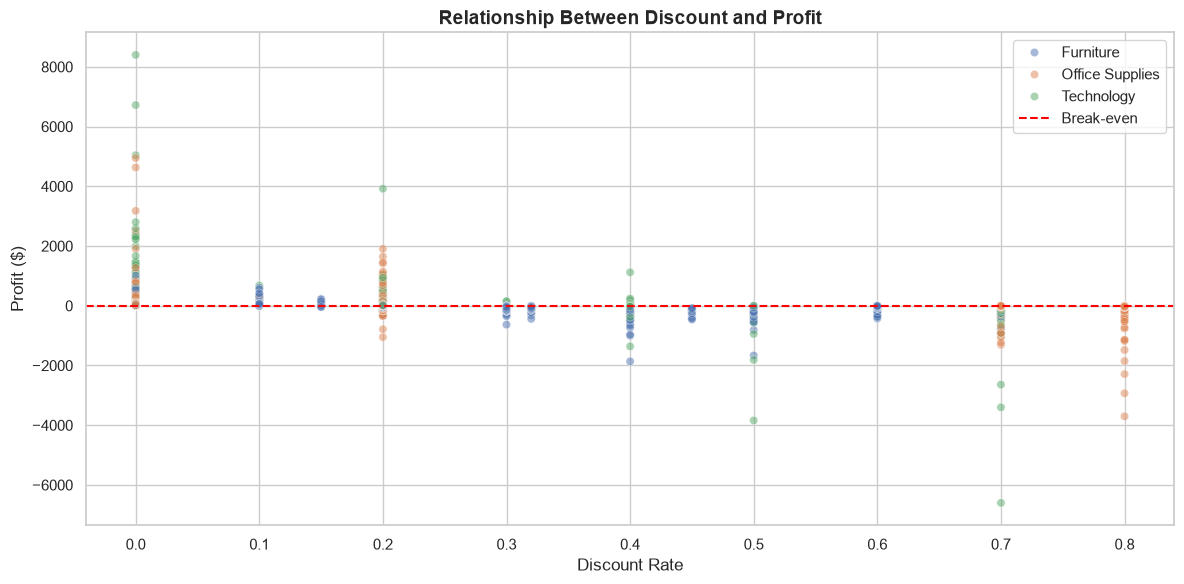

In [30]:

# Step 11.2: Discount vs Profit Visualization

plt.figure(figsize=(12, 6))

sns.scatterplot(
    data=df_clean,
    x="Discount",
    y="Profit",
    hue="Category",
    alpha=0.5
)

plt.axhline(
    y=0,
    color="red",
    linestyle="--",
    label="Break-even"
)

plt.title(
    "Relationship Between Discount and Profit",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel("Discount Rate")
plt.ylabel("Profit ($)")
plt.legend()
plt.tight_layout()
plt.show()


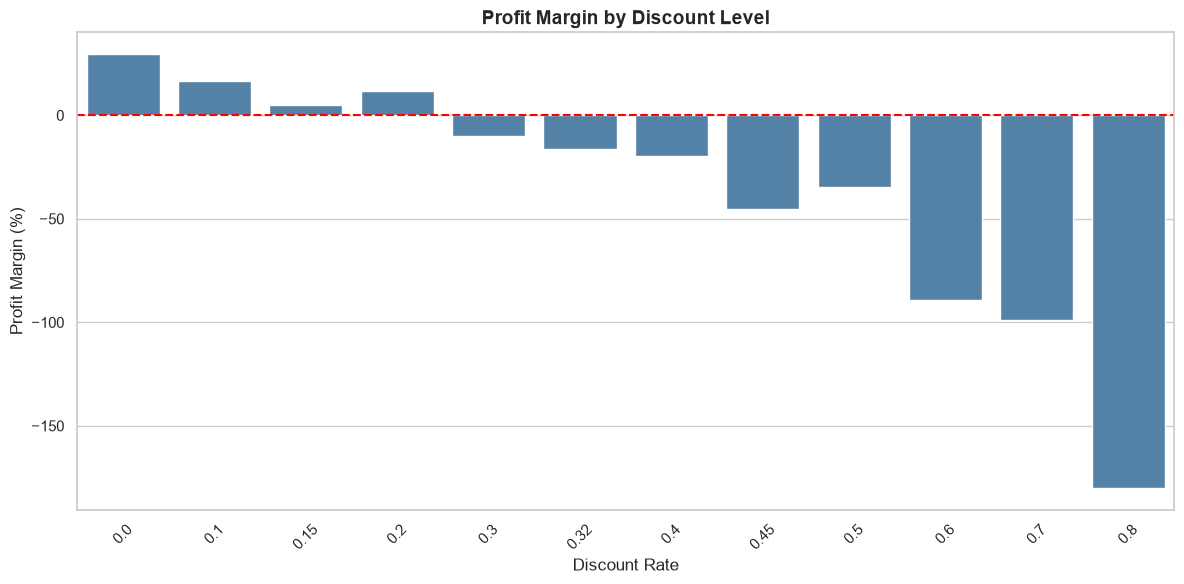

In [31]:

# Step 11.3: Profit Margin by Discount Level

plt.figure(figsize=(12, 6))

sns.barplot(
    data=discount_analysis,
    x="Discount",
    y="Profit_Margin",
    color="steelblue"
)

plt.axhline(
    y=0,
    color="red",
    linestyle="--"
)

plt.title(
    "Profit Margin by Discount Level",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel("Discount Rate")
plt.ylabel("Profit Margin (%)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


In [32]:

# Step 13: Export Cleaned Dataset

# Convert Year-Month to string for CSV compatibility
df_export = df_clean.copy()

df_export["Year-Month"] = (
    df_export["Year-Month"].astype(str)
)

# Export cleaned dataset
df_export.to_csv(
    "superstore_sales_cleaned.csv",
    index=False
)

print("Cleaned dataset exported successfully!")
print("Final dataset shape:", df_export.shape)


Cleaned dataset exported successfully!
Final dataset shape: (9994, 25)
